In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
folder = "/content/drive/MyDrive/Mineral Projecet"

In [4]:
K_file = f"{folder}/K_perc.tiff"
eU_file = f"{folder}/eU_ppm.tiff"
eTh_file = f"{folder}/eTh_ppm.tiff"
Dose_file = f"{folder}/Dose_rate_TC.tiff"

In [5]:
# File names
# Define file paths
K_file = f"{folder}/K_perc.tiff"
eU_file = f"{folder}/eU_ppm.tiff"
eTh_file = f"{folder}/eTh_ppm.tiff"
Dose_file = f"{folder}/Dose_rate_TC.tiff"

# Read the raster data
with rasterio.open(K_file) as src:
    K = src.read(1)
    K_profile = src.profile

with rasterio.open(eU_file) as src:
    eU = src.read(1)
    eU_profile = src.profile

with rasterio.open(eTh_file) as src:
    eTh = src.read(1)
    eTh_profile = src.profile

with rasterio.open(Dose_file) as src:
    Dose = src.read(1)
    Dose_profile = src.profile

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [6]:
rasters = {
    "K": K,
    "eU": eU,
    "eTh": eTh,
    "Dose": Dose
}

for name, data in rasters.items():
    print(name, "→ Shape:", data.shape)

print("\nCRS:", K_profile["crs"])
print("Resolution:", K_profile["transform"].a, "x", abs(K_profile["transform"].e))

K → Shape: (3715, 3160)
eU → Shape: (3715, 3160)
eTh → Shape: (3715, 3160)
Dose → Shape: (3715, 3160)

CRS: EPSG:32643
Resolution: 60.0 x 60.0


In [7]:
for name, data in rasters.items():
    print(f"\n{name}")
    print("Minimum:", np.nanmin(data))
    print("Maximum:", np.nanmax(data))
    print("Mean:", np.nanmean(data))
    print("Median:", np.nanmedian(data))


K
Minimum: 0.10000000149011612
Maximum: 1.70141e+38
Mean: 1.4343459939264397e+37
Median: 1.5231850743293762

eU
Minimum: 0.10000000149011612
Maximum: 1.70141e+38
Mean: 1.4343459939264397e+37
Median: 1.8450783491134644

eTh
Minimum: 0.10000000149011612
Maximum: 1.70141e+38
Mean: 1.4343459939264397e+37
Median: 9.379540920257568

Dose
Minimum: 0.10000000149011612
Maximum: 1.70141e+38
Mean: 1.4343459939264397e+37
Median: 71.87421417236328


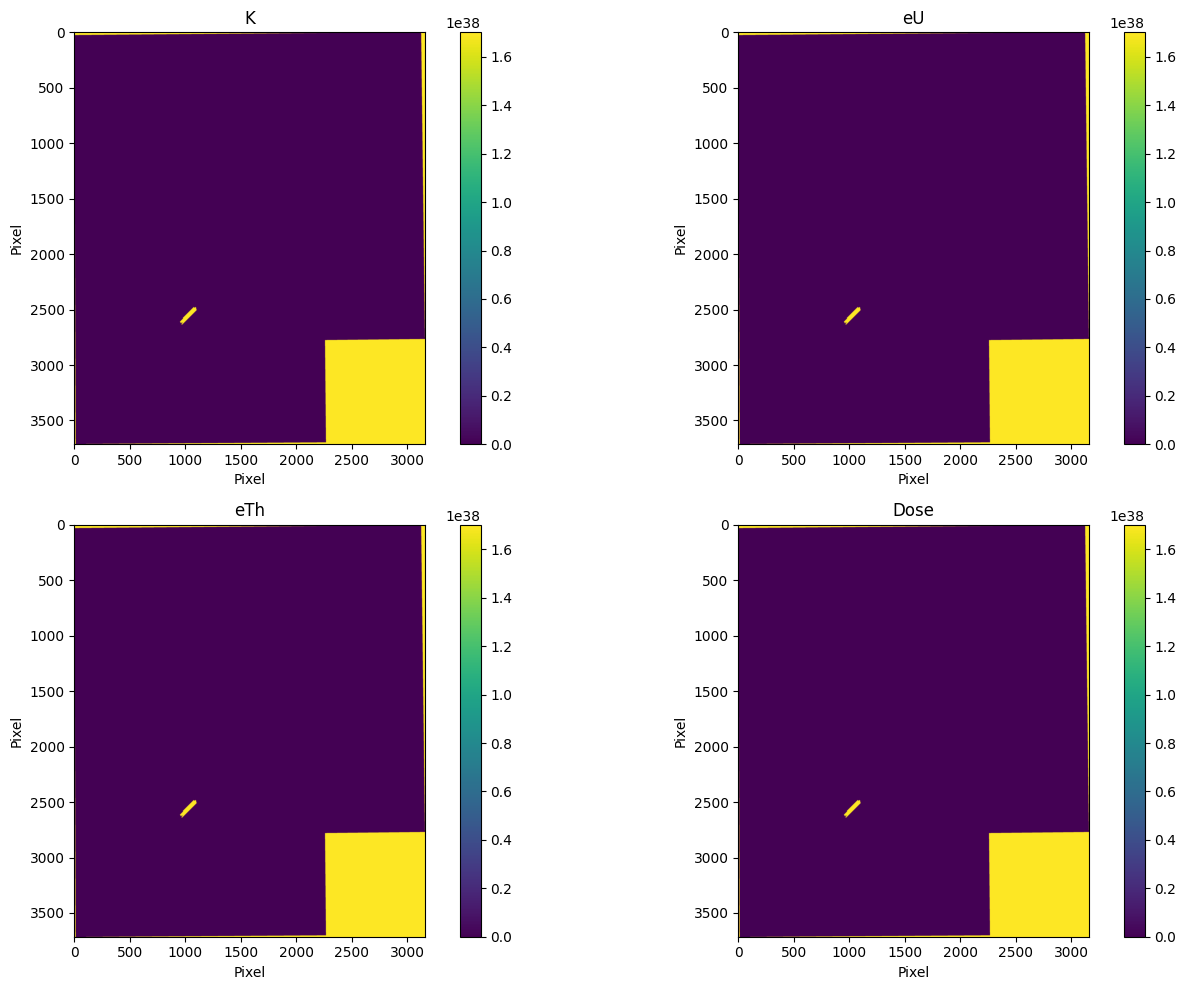

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, data) in zip(axes.ravel(), rasters.items()):
    im = ax.imshow(data, cmap="viridis")
    ax.set_title(name)
    ax.set_xlabel("Pixel")
    ax.set_ylabel("Pixel")
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

In [9]:
# Replace NoData values with NaN
for name, data in rasters.items():
    nodata = {
        "K": K_profile["nodata"],
        "eU": eU_profile["nodata"],
        "eTh": eTh_profile["nodata"],
        "Dose": Dose_profile["nodata"]
    }[name]

    rasters[name] = np.where(data == nodata, np.nan, data)

print("NoData values removed.")

NoData values removed.


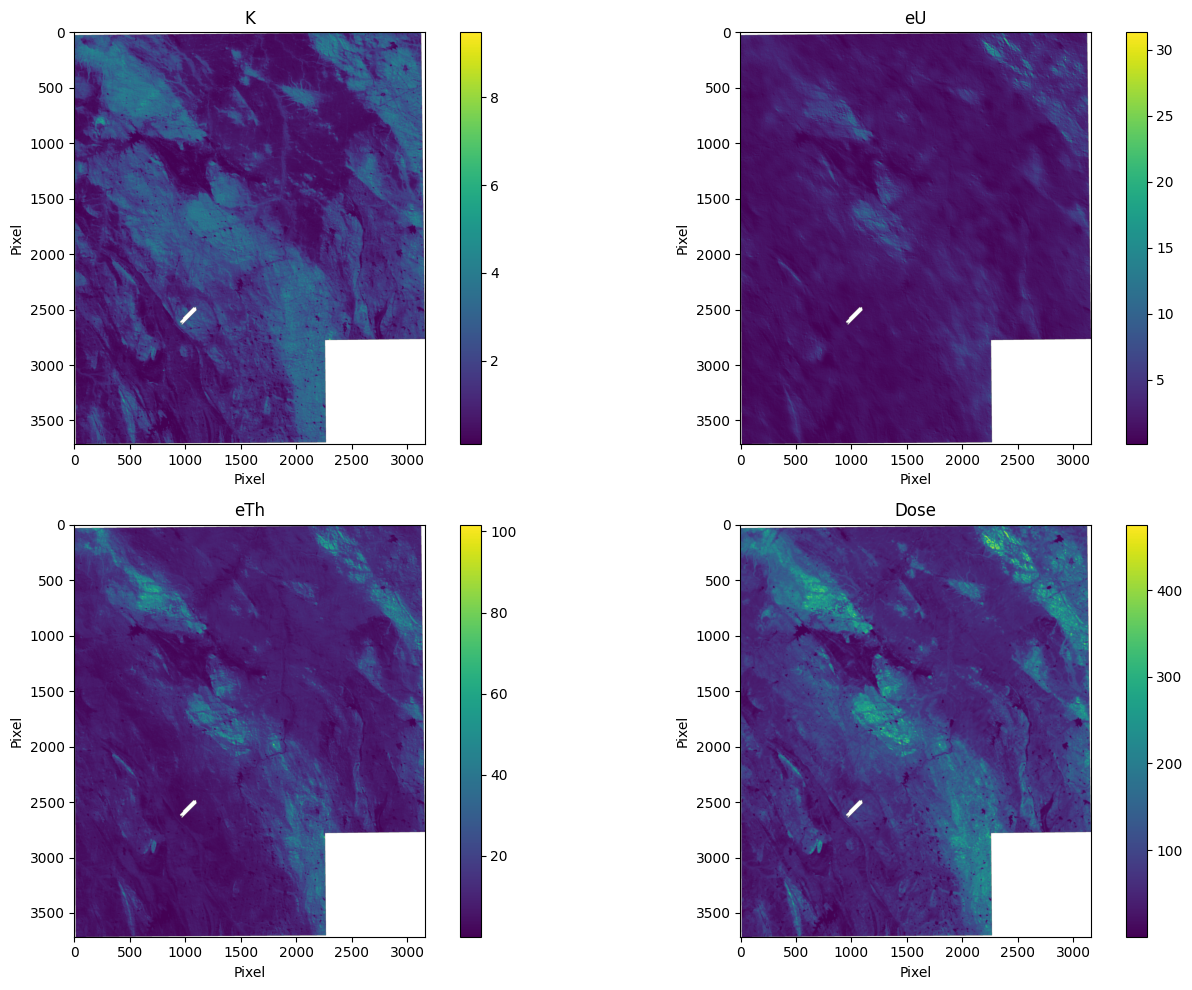

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, data) in zip(axes.ravel(), rasters.items()):
    im = ax.imshow(data, cmap="viridis")
    ax.set_title(name)
    ax.set_xlabel("Pixel")
    ax.set_ylabel("Pixel")
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

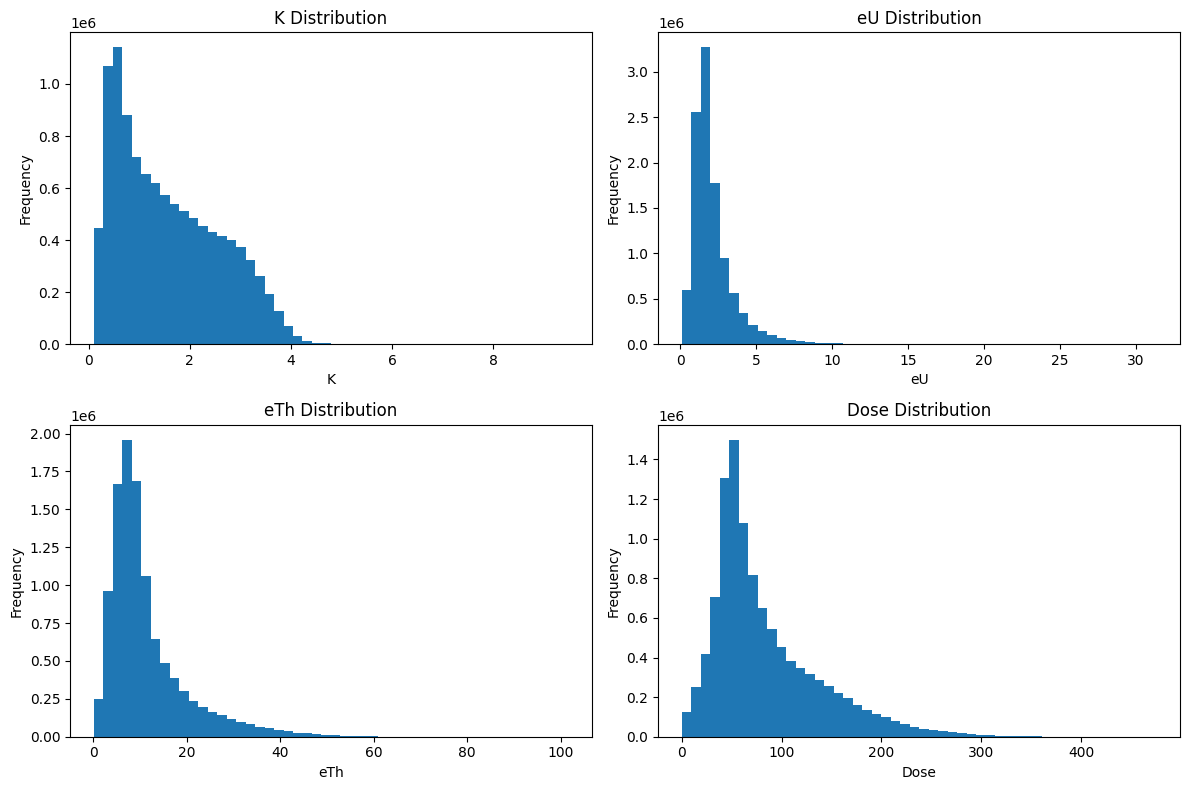

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, data) in zip(axes.ravel(), rasters.items()):
    ax.hist(data[~np.isnan(data)].flatten(), bins=50)
    ax.set_title(f"{name} Distribution")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [12]:
# Create a sample for correlation analysis
df = pd.DataFrame({
    "K": rasters["K"].flatten(),
    "eU": rasters["eU"].flatten(),
    "eTh": rasters["eTh"].flatten(),
    "Dose": rasters["Dose"].flatten()
}).dropna()

print(df.corr())

             K        eU       eTh      Dose
K     1.000000  0.660577  0.721491  0.899204
eU    0.660577  1.000000  0.812686  0.841519
eTh   0.721491  0.812686  1.000000  0.930461
Dose  0.899204  0.841519  0.930461  1.000000


In [13]:
for name, data in rasters.items():
    mean = np.nanmean(data)
    std = np.nanstd(data)
    threshold = mean + 2 * std

    print(f"{name}:")
    print(f"Mean = {mean:.2f}")
    print(f"Std = {std:.2f}")
    print(f"Anomaly threshold = {threshold:.2f}\n")

K:
Mean = 1.57
Std = 1.01
Anomaly threshold = 3.60

eU:
Mean = 2.13
Std = 1.47
Anomaly threshold = 5.07

eTh:
Mean = 11.36
Std = 8.49
Anomaly threshold = 28.34

Dose:
Mean = 83.98
Std = 54.23
Anomaly threshold = 192.44



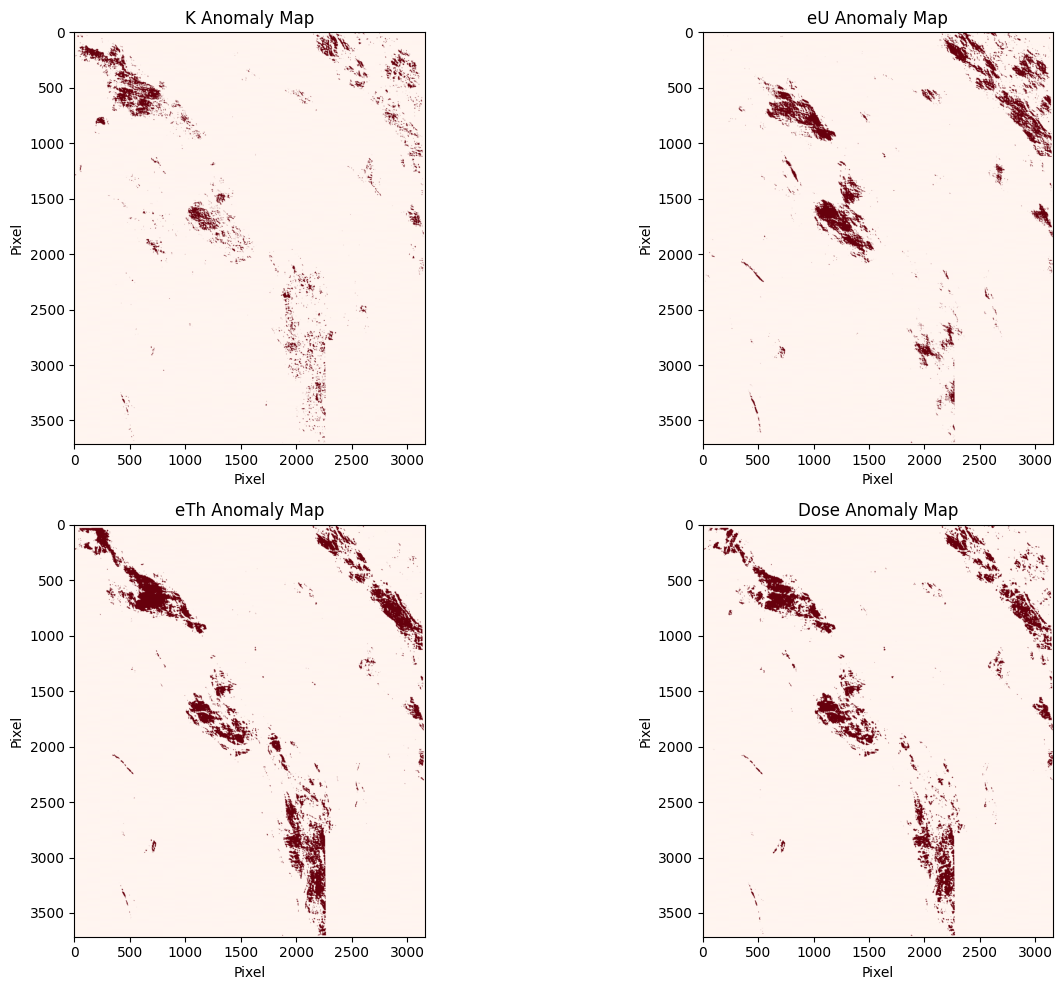

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

thresholds = {
    "K": 3.60,
    "eU": 5.07,
    "eTh": 28.34,
    "Dose": 192.44
}

for ax, (name, data) in zip(axes.ravel(), rasters.items()):
    anomaly = data > thresholds[name]

    ax.imshow(anomaly, cmap="Reds")
    ax.set_title(f"{name} Anomaly Map")
    ax.set_xlabel("Pixel")
    ax.set_ylabel("Pixel")

plt.tight_layout()
plt.show()

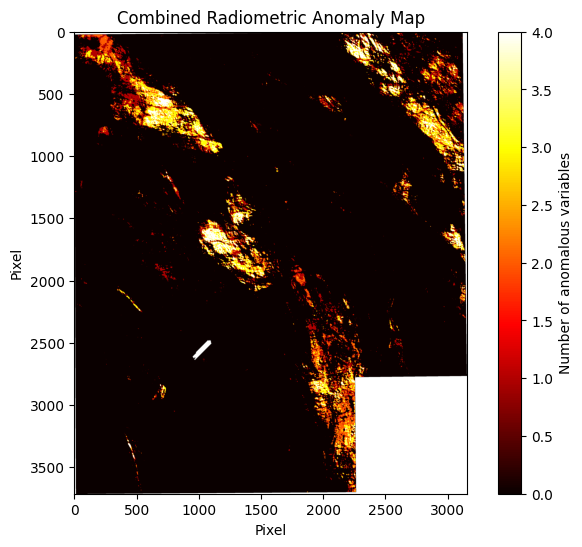

In [15]:
thresholds = {
    "K": 3.60,
    "eU": 5.07,
    "eTh": 28.34,
    "Dose": 192.44
}

anomaly_count = np.zeros_like(rasters["K"])

for name, data in rasters.items():
    anomaly_count += np.where(data > thresholds[name], 1, 0)

anomaly_count[np.isnan(rasters["K"])] = np.nan

plt.figure(figsize=(8, 6))
plt.imshow(anomaly_count, cmap="hot")
plt.colorbar(label="Number of anomalous variables")
plt.title("Combined Radiometric Anomaly Map")
plt.xlabel("Pixel")
plt.ylabel("Pixel")
plt.show()

In [16]:
feature_data = pd.DataFrame({
    "K": rasters["K"].flatten(),
    "eU": rasters["eU"].flatten(),
    "eTh": rasters["eTh"].flatten(),
    "Dose": rasters["Dose"].flatten(),
    "K_anomaly": (rasters["K"] > thresholds["K"]).astype(int).flatten(),
    "eU_anomaly": (rasters["eU"] > thresholds["eU"]).astype(int).flatten(),
    "eTh_anomaly": (rasters["eTh"] > thresholds["eTh"]).astype(int).flatten(),
    "Dose_anomaly": (rasters["Dose"] > thresholds["Dose"]).astype(int).flatten(),
    "anomaly_count": anomaly_count.flatten()
})

feature_data = feature_data.dropna()

print(feature_data.head())
print("\nShape:", feature_data.shape)

             K        eU        eTh        Dose  K_anomaly  eU_anomaly  \
3083  1.989145  2.600578  13.232245  114.722801          0           0   
3084  2.134372  2.688154  14.675505  122.779831          0           0   
3085  2.275435  2.796886  16.155146  130.732162          0           0   
3086  2.404321  2.867072  17.525503  137.632767          0           0   
3087  2.507145  2.836946  18.655912  142.416412          0           0   

      eTh_anomaly  Dose_anomaly  anomaly_count  
3083            0             0            0.0  
3084            0             0            0.0  
3085            0             0            0.0  
3086            0             0            0.0  
3087            0             0            0.0  

Shape: (10749729, 9)


In [17]:
rows, cols = np.where(~np.isnan(rasters["K"]))

feature_data["row"] = rows
feature_data["col"] = cols

print(feature_data.head())


             K        eU        eTh        Dose  K_anomaly  eU_anomaly  \
3083  1.989145  2.600578  13.232245  114.722801          0           0   
3084  2.134372  2.688154  14.675505  122.779831          0           0   
3085  2.275435  2.796886  16.155146  130.732162          0           0   
3086  2.404321  2.867072  17.525503  137.632767          0           0   
3087  2.507145  2.836946  18.655912  142.416412          0           0   

      eTh_anomaly  Dose_anomaly  anomaly_count  row   col  
3083            0             0            0.0    0  3083  
3084            0             0            0.0    0  3084  
3085            0             0            0.0    0  3085  
3086            0             0            0.0    0  3086  
3087            0             0            0.0    0  3087  


In [18]:
feature_data = feature_data.reset_index(drop=True)

print(feature_data.head())
print("\nShape:", feature_data.shape)

          K        eU        eTh        Dose  K_anomaly  eU_anomaly  \
0  1.989145  2.600578  13.232245  114.722801          0           0   
1  2.134372  2.688154  14.675505  122.779831          0           0   
2  2.275435  2.796886  16.155146  130.732162          0           0   
3  2.404321  2.867072  17.525503  137.632767          0           0   
4  2.507145  2.836946  18.655912  142.416412          0           0   

   eTh_anomaly  Dose_anomaly  anomaly_count  row   col  
0            0             0            0.0    0  3083  
1            0             0            0.0    0  3084  
2            0             0            0.0    0  3085  
3            0             0            0.0    0  3086  
4            0             0            0.0    0  3087  

Shape: (10749729, 11)


In [19]:
from sklearn.preprocessing import StandardScaler

features = ["K", "eU", "eTh", "Dose"]

scaler = StandardScaler()

feature_data[features] = scaler.fit_transform(feature_data[features])

print(feature_data[features].head())

          K        eU       eTh      Dose
0  0.416845  0.318784  0.220077  0.566862
1  0.559950  0.378453  0.390061  0.715439
2  0.698952  0.452535  0.564329  0.862086
3  0.825955  0.500356  0.725727  0.989338
4  0.927277  0.479830  0.858864  1.077551


In [20]:
print(feature_data[["K", "eU", "eTh", "Dose"]].mean())
print(feature_data[["K", "eU", "eTh", "Dose"]].std())

K       4.422794e-17
eU      1.290669e-16
eTh    -1.456095e-15
Dose    3.104628e-16
dtype: float64
K       1.0
eU      1.0
eTh     1.0
Dose    1.0
dtype: float64


In [21]:
rows, cols = np.where(~np.isnan(rasters["K"]))

feature_data["row"] = rows
feature_data["col"] = cols

print(feature_data.head())

          K        eU       eTh      Dose  K_anomaly  eU_anomaly  eTh_anomaly  \
0  0.416845  0.318784  0.220077  0.566862          0           0            0   
1  0.559950  0.378453  0.390061  0.715439          0           0            0   
2  0.698952  0.452535  0.564329  0.862086          0           0            0   
3  0.825955  0.500356  0.725727  0.989338          0           0            0   
4  0.927277  0.479830  0.858864  1.077551          0           0            0   

   Dose_anomaly  anomaly_count  row   col  
0             0            0.0    0  3083  
1             0            0.0    0  3084  
2             0            0.0    0  3085  
3             0            0.0    0  3086  
4             0            0.0    0  3087  


In [22]:
feature_data = feature_data.reset_index(drop=True)

print(feature_data.head())
print("Shape:", feature_data.shape)

          K        eU       eTh      Dose  K_anomaly  eU_anomaly  eTh_anomaly  \
0  0.416845  0.318784  0.220077  0.566862          0           0            0   
1  0.559950  0.378453  0.390061  0.715439          0           0            0   
2  0.698952  0.452535  0.564329  0.862086          0           0            0   
3  0.825955  0.500356  0.725727  0.989338          0           0            0   
4  0.927277  0.479830  0.858864  1.077551          0           0            0   

   Dose_anomaly  anomaly_count  row   col  
0             0            0.0    0  3083  
1             0            0.0    0  3084  
2             0            0.0    0  3085  
3             0            0.0    0  3086  
4             0            0.0    0  3087  
Shape: (10749729, 11)


In [23]:
from sklearn.preprocessing import StandardScaler

features = ["K", "eU", "eTh", "Dose"]

scaler = StandardScaler()

feature_data[features] = scaler.fit_transform(feature_data[features])

print(feature_data[features].head())

          K        eU       eTh      Dose
0  0.416845  0.318784  0.220077  0.566862
1  0.559950  0.378453  0.390061  0.715439
2  0.698952  0.452535  0.564329  0.862086
3  0.825955  0.500356  0.725727  0.989338
4  0.927277  0.479830  0.858864  1.077551


In [24]:
print(feature_data[features].mean())
print(feature_data[features].std())

K       2.159576e-17
eU      5.738422e-17
eTh     9.101522e-17
Dose    6.408927e-18
dtype: float64
K       1.0
eU      1.0
eTh     1.0
Dose    1.0
dtype: float64


In [25]:
output_file = f"{folder}/radiometric_features.parquet"

feature_data.to_parquet(output_file, index=False)

print("Radiometric feature dataset saved successfully!")

Radiometric feature dataset saved successfully!


In [26]:
import pandas as pd

feature_data = pd.read_parquet(
    "/content/drive/MyDrive/Mineral Projecet/radiometric_features.parquet"
)

print("Radiometric feature dataset loaded successfully!")
print("Shape:", feature_data.shape)

Radiometric feature dataset loaded successfully!
Shape: (10749729, 11)


In [27]:
print("Feature names:")
print(feature_data.columns.tolist())

print("\nFirst 5 rows:")
print(feature_data.head())

Feature names:
['K', 'eU', 'eTh', 'Dose', 'K_anomaly', 'eU_anomaly', 'eTh_anomaly', 'Dose_anomaly', 'anomaly_count', 'row', 'col']

First 5 rows:
          K        eU       eTh      Dose  K_anomaly  eU_anomaly  eTh_anomaly  \
0  0.416845  0.318784  0.220077  0.566862          0           0            0   
1  0.559950  0.378453  0.390061  0.715439          0           0            0   
2  0.698952  0.452535  0.564329  0.862086          0           0            0   
3  0.825955  0.500356  0.725727  0.989338          0           0            0   
4  0.927277  0.479830  0.858864  1.077551          0           0            0   

   Dose_anomaly  anomaly_count  row   col  
0             0            0.0    0  3083  
1             0            0.0    0  3084  
2             0            0.0    0  3085  
3             0            0.0    0  3086  
4             0            0.0    0  3087  


In [28]:
print(feature_data.describe())

                  K            eU           eTh          Dose     K_anomaly  \
count  1.074973e+07  1.074973e+07  1.074973e+07  1.074973e+07  1.074973e+07   
mean   2.159576e-17  5.738422e-17  9.101522e-17  6.408927e-18  2.955693e-02   
std    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.693615e-01   
min   -1.444699e+00 -1.384947e+00 -1.326609e+00 -1.546863e+00  0.000000e+00   
25%   -8.841032e-01 -5.907096e-01 -6.324534e-01 -6.842110e-01  0.000000e+00   
50%   -1.974019e-01 -2.654422e-01 -3.014310e-01 -3.226834e-01  0.000000e+00   
75%    7.606544e-01  2.712925e-01  2.786951e-01  4.744650e-01  0.000000e+00   
max    7.796056e+00  1.989902e+01  1.062955e+01  7.214817e+00  1.000000e+00   

         eU_anomaly   eTh_anomaly  Dose_anomaly  anomaly_count           row  \
count  1.074973e+07  1.074973e+07  1.074973e+07   1.074973e+07  1.074973e+07   
mean   4.522207e-02  5.752015e-02  5.283640e-02   1.851356e-01  1.754952e+03   
std    2.077909e-01  2.328338e-01  2.237068e-01 

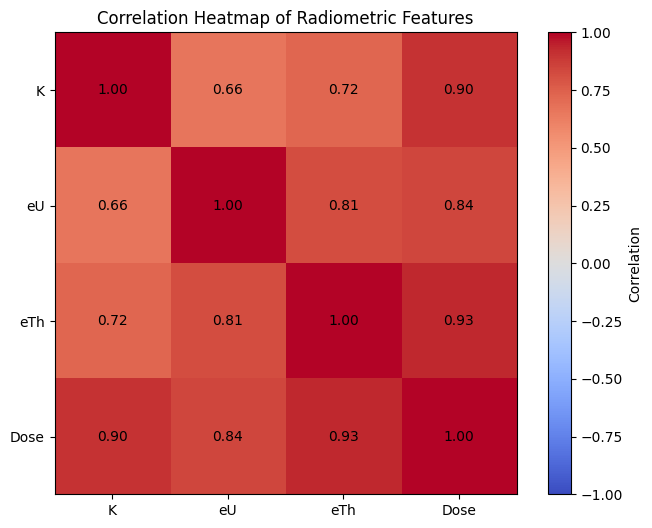

In [29]:
import matplotlib.pyplot as plt

correlation = feature_data[["K", "eU", "eTh", "Dose"]].corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")
plt.xticks(range(4), correlation.columns)
plt.yticks(range(4), correlation.columns)

plt.title("Correlation Heatmap of Radiometric Features")

for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.show()

In [30]:

anomaly_features = [
    "K_anomaly",
    "eU_anomaly",
    "eTh_anomaly",
    "Dose_anomaly"
]

anomaly_summary = pd.DataFrame({
    "Parameter": anomaly_features,
    "Anomalous_Pixels": [
        int(feature_data[col].sum())
        for col in anomaly_features
    ],
    "Percentage": [
        feature_data[col].mean() * 100
        for col in anomaly_features
    ]
})

anomaly_summary["Percentage"] = anomaly_summary["Percentage"].round(2)

print(anomaly_summary.to_string(index=False))


   Parameter  Anomalous_Pixels  Percentage
   K_anomaly            317729        2.96
  eU_anomaly            486125        4.52
 eTh_anomaly            618326        5.75
Dose_anomaly            567977        5.28


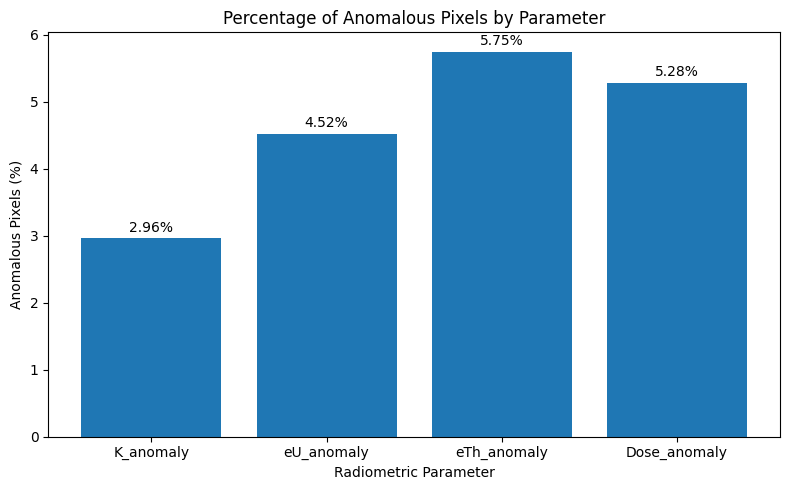

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    anomaly_summary["Parameter"],
    anomaly_summary["Percentage"]
)

plt.title("Percentage of Anomalous Pixels by Parameter")
plt.xlabel("Radiometric Parameter")
plt.ylabel("Anomalous Pixels (%)")

for i, value in enumerate(anomaly_summary["Percentage"]):
    plt.text(i, value + 0.1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [32]:

anomaly_count_summary = (
    feature_data["anomaly_count"]
    .value_counts()
    .sort_index()
    .reindex(range(5), fill_value=0)
)

anomaly_count_summary.index.name = "Number_of_Anomalous_Parameters"
anomaly_count_summary.name = "Pixel_Count"

print(anomaly_count_summary)

print("\nPercentage of pixels:")
print((anomaly_count_summary / len(feature_data) * 100).round(2))


Number_of_Anomalous_Parameters
0    9822937
1     343303
2     218544
3     250014
4     114931
Name: Pixel_Count, dtype: int64

Percentage of pixels:
Number_of_Anomalous_Parameters
0    91.38
1     3.19
2     2.03
3     2.33
4     1.07
Name: Pixel_Count, dtype: float64


In [33]:
print("Dataset shape:", feature_data.shape)

print("\nMissing values per column:")
print(feature_data.isna().sum())

print("\nTotal missing values:", feature_data.isna().sum().sum())

print("\nFeature data types:")
print(feature_data.dtypes)

Dataset shape: (10749729, 11)

Missing values per column:
K                0
eU               0
eTh              0
Dose             0
K_anomaly        0
eU_anomaly       0
eTh_anomaly      0
Dose_anomaly     0
anomaly_count    0
row              0
col              0
dtype: int64

Total missing values: 0

Feature data types:
K                float64
eU               float64
eTh              float64
Dose             float64
K_anomaly          int64
eU_anomaly         int64
eTh_anomaly        int64
Dose_anomaly       int64
anomaly_count    float64
row                int64
col                int64
dtype: object


## Feature Analytics — Key Findings

- The radiometric dataset contains four continuous features: potassium (K), equivalent uranium (eU), equivalent thorium (eTh), and dose rate (Dose). These features were standardized before further analysis.
- Correlation analysis showed positive relationships between all four features. The strongest correlation was between eTh and Dose (0.93), followed by K and Dose (0.90).
- Anomaly frequency analysis showed that eTh had the highest percentage of anomalous pixels (5.75%), while K had the lowest (2.96%).
- Combined anomaly analysis showed that 8.62% of valid pixels had at least one anomalous radiometric parameter.
- The final feature dataset contains 10,749,729 rows and 11 columns, with no missing values.

**Conclusion:** The radiometric data has been analysed statistically, spatially, and through anomaly detection. The resulting feature dataset is prepared for subsequent integration with other geoscientific datasets for mineral prospectivity modelling.

*Note: Statistical radiometric anomalies indicate unusual measurements and do not independently confirm the presence of mineral deposits.*

In [34]:

# CNN Step 1: Build a separate four-channel input stack
# Existing notebook variables remain unchanged.

import numpy as np

channel_names = ["K", "eU", "eTh", "Dose"]

# Confirm all four required layers exist
missing = [name for name in channel_names if name not in rasters]
if missing:
    raise ValueError(f"Missing raster layers: {missing}")

# Verify that all layers have the same spatial shape
shapes = [rasters[name].shape for name in channel_names]
if len(set(shapes)) != 1:
    raise ValueError(f"Raster shapes do not match: {shapes}")

# Create a separate float32 stack: rows × columns × channels
raw_stack = np.stack(
    [np.asarray(rasters[name], dtype=np.float32)
     for name in channel_names],
    axis=-1
)

# A pixel is valid only if all four channels are finite
valid_mask = np.isfinite(raw_stack).all(axis=-1)

# Scale each channel independently using valid-pixel percentiles.
# This creates new data; it does not alter the original rasters.
cnn_stack = np.zeros_like(raw_stack, dtype=np.float32)

for i, name in enumerate(channel_names):
    values = raw_stack[..., i][valid_mask]

    if values.size == 0:
        raise ValueError(f"No valid pixels found for {name}")

    low, high = np.percentile(values, [1, 99])

    if high <= low:
        raise ValueError(f"Cannot scale constant layer: {name}")

    layer = np.clip(raw_stack[..., i], low, high)
    cnn_stack[..., i] = (layer - low) / (high - low)

# Invalid pixels are set to zero and separately tracked by valid_mask
cnn_stack[~valid_mask] = 0.0

print("CNN input shape (rows, columns, channels):", cnn_stack.shape)
print("Channels:", channel_names)
print("Valid pixels:", int(valid_mask.sum()))
print("Invalid pixels:", int((~valid_mask).sum()))
print("Value range:", float(cnn_stack.min()), "to",
      float(cnn_stack.max()))


CNN input shape (rows, columns, channels): (3715, 3160, 4)
Channels: ['K', 'eU', 'eTh', 'Dose']
Valid pixels: 10749729
Invalid pixels: 989671
Value range: 0.0 to 1.0


In [35]:

# CNN Step 2: Sample valid spatial patches
# Does not modify cnn_stack, rasters, or feature_data.

PATCH_SIZE = 32
N_PATCHES = 2000
MIN_VALID_FRACTION = 0.95
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

rows, cols, channels = cnn_stack.shape
half = PATCH_SIZE // 2

# Candidate patch centres, excluding raster borders
candidate_rows = np.arange(half, rows - half)
candidate_cols = np.arange(half, cols - half)

patches = []
patch_centres = []
attempts = 0
max_attempts = N_PATCHES * 30

while len(patches) < N_PATCHES and attempts < max_attempts:
    attempts += 1

    r = int(rng.choice(candidate_rows))
    c = int(rng.choice(candidate_cols))

    r0, c0 = r - half, c - half
    patch_mask = valid_mask[
        r0:r0 + PATCH_SIZE,
        c0:c0 + PATCH_SIZE
    ]

    if patch_mask.mean() < MIN_VALID_FRACTION:
        continue

    patch = cnn_stack[
        r0:r0 + PATCH_SIZE,
        c0:c0 + PATCH_SIZE,
        :
    ]

    patches.append(patch)
    patch_centres.append((r, c))

if len(patches) < 100:
    raise RuntimeError(
        f"Only {len(patches)} valid patches found. "
        "Check the valid-pixel mask before proceeding."
    )

X_patches = np.stack(patches).astype(np.float32)
patch_centres = np.asarray(patch_centres, dtype=np.int32)

print("Patch array shape:", X_patches.shape)
print("Patch centres shape:", patch_centres.shape)
print("Patch size:", PATCH_SIZE, "x", PATCH_SIZE)
print("Number of channels:", channels)
print("Valid patches sampled:", len(X_patches))
print("Patch value range:", X_patches.min(), "to", X_patches.max())


Patch array shape: (2000, 32, 32, 4)
Patch centres shape: (2000, 2)
Patch size: 32 x 32
Number of channels: 4
Valid patches sampled: 2000
Patch value range: 0.0 to 1.0


In [36]:
# Step 3: Check TensorFlow availability

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("CNN framework is ready.")

    gpus = tf.config.list_physical_devices("GPU")
    print("GPU available:", bool(gpus))

    if gpus:
        print("GPU devices:", gpus)
    else:
        print("Using CPU for model training.")

except ImportError:
    print("TensorFlow is not installed in this runtime.")
    print("Do not install anything yet; send me this output first.")

TensorFlow version: 2.21.0
CNN framework is ready.
GPU available: False
Using CPU for model training.


In [37]:
# Step 4: Define a small convolutional autoencoder

from tensorflow.keras import layers, Model

PATCH_SIZE = 32
N_CHANNELS = 4

inputs = layers.Input(shape=(PATCH_SIZE, PATCH_SIZE, N_CHANNELS))

# Encoder: learn spatial patterns in the radiometric channels
x = layers.Conv2D(16, 3, activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D(2, padding="same")(x)

x = layers.Conv2D(8, 3, activation="relu", padding="same")(x)
encoded = layers.MaxPooling2D(2, padding="same", name="encoded_features")(x)

# Decoder: reconstruct the original four-channel patch
x = layers.Conv2D(8, 3, activation="relu", padding="same")(encoded)
x = layers.UpSampling2D(2)(x)

x = layers.Conv2D(16, 3, activation="relu", padding="same")(x)
x = layers.UpSampling2D(2)(x)

outputs = layers.Conv2D(
    N_CHANNELS, 3, activation="sigmoid", padding="same"
)(x)

autoencoder = Model(inputs, outputs, name="radiometric_cnn_autoencoder")

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "radiometric_cnn_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoded_features (MaxPooling2D) │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 4)      │           580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,084 (15.95 KB)

 Trainable params: 4,084 (15.95 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Step 5: Spatially separated training and validation split

# Reserve the eastern 20% of the raster for validation.
validation_boundary = int(0.80 * cnn_stack.shape[1])

train_mask = patch_centres[:, 1] < validation_boundary
val_mask = patch_centres[:, 1] >= validation_boundary

X_train = X_patches[train_mask]
X_val = X_patches[val_mask]

print("Training patches:", X_train.shape)
print("Validation patches:", X_val.shape)
print("Validation boundary (column):", validation_boundary)

if len(X_train) == 0 or len(X_val) == 0:
    raise ValueError(
        "One split is empty. We need to adjust the spatial split."
    )

Training patches: (1682, 32, 32, 4)
Validation patches: (318, 32, 32, 4)
Validation boundary (column): 2528


In [39]:
# Step 6: Train the CNN autoencoder

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

history = autoencoder.fit(
    X_train, X_train,
    validation_data=(X_val, X_val),
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=True,
    verbose=1
)

print("\nTraining completed.")
print("Epochs run:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

Epoch 1/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 0.0501 - val_loss: 0.0143
Epoch 2/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0066 - val_loss: 0.0073
Epoch 3/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0038 - val_loss: 0.0056
Epoch 4/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0031 - val_loss: 0.0051
Epoch 5/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0027 - val_loss: 0.0046
Epoch 6/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 0.0024 - val_loss: 0.0041
Epoch 7/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0022 - val_loss: 0.0036
Epoch 8/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0019 - val_loss: 0.0027
Epoch 9/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 10/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.0016 - val_loss: 0.0031
Epoch 11/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0015 - val_loss: 0.0028
Epoch 12/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 

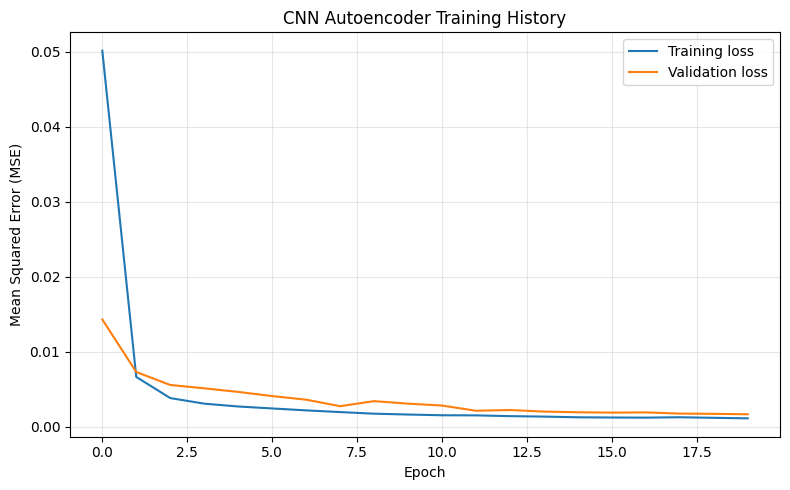

In [40]:
# Step 7: Visualize CNN training and validation loss

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("CNN Autoencoder Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Step 8: Calculate reconstruction errors for sampled patches

X_reconstructed = autoencoder.predict(
    X_patches,
    batch_size=16,
    verbose=1
)

# Mean squared reconstruction error for each patch
patch_errors = np.mean(
    np.square(X_patches - X_reconstructed),
    axis=(1, 2, 3)
)

print("Number of patch errors:", len(patch_errors))
print("Minimum error:", float(np.min(patch_errors)))
print("Mean error:", float(np.mean(patch_errors)))
print("Median error:", float(np.median(patch_errors)))
print("95th percentile:", float(np.percentile(patch_errors, 95)))
print("Maximum error:", float(np.max(patch_errors)))

125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
Number of patch errors: 2000
Minimum error: 0.00021785908029414713
Mean error: 0.0011355099268257618
Median error: 0.0007846006192266941
95th percentile: 0.0033544437028467655
Maximum error: 0.008139504119753838


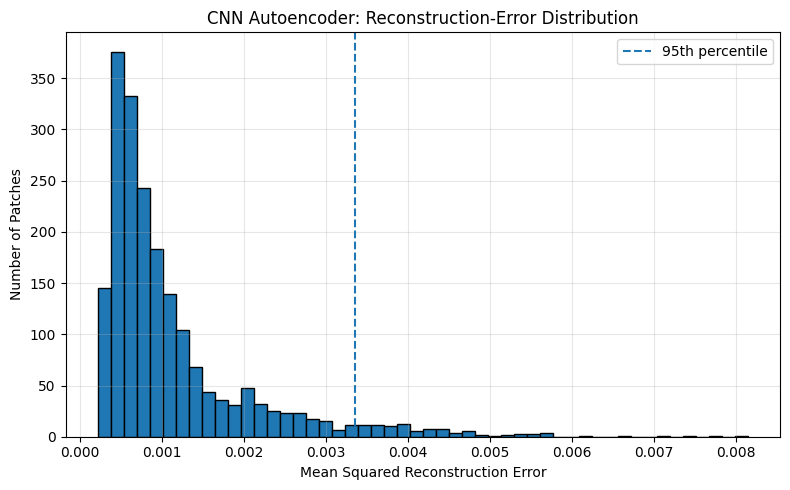

In [42]:
# Step 9: Visualize reconstruction-error distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(patch_errors, bins=50, edgecolor="black")
plt.axvline(
    np.percentile(patch_errors, 95),
    linestyle="--",
    label="95th percentile"
)

plt.xlabel("Mean Squared Reconstruction Error")
plt.ylabel("Number of Patches")
plt.title("CNN Autoencoder: Reconstruction-Error Distribution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

95th percentile error threshold: 0.0033544437028467655
High-error patches: 100


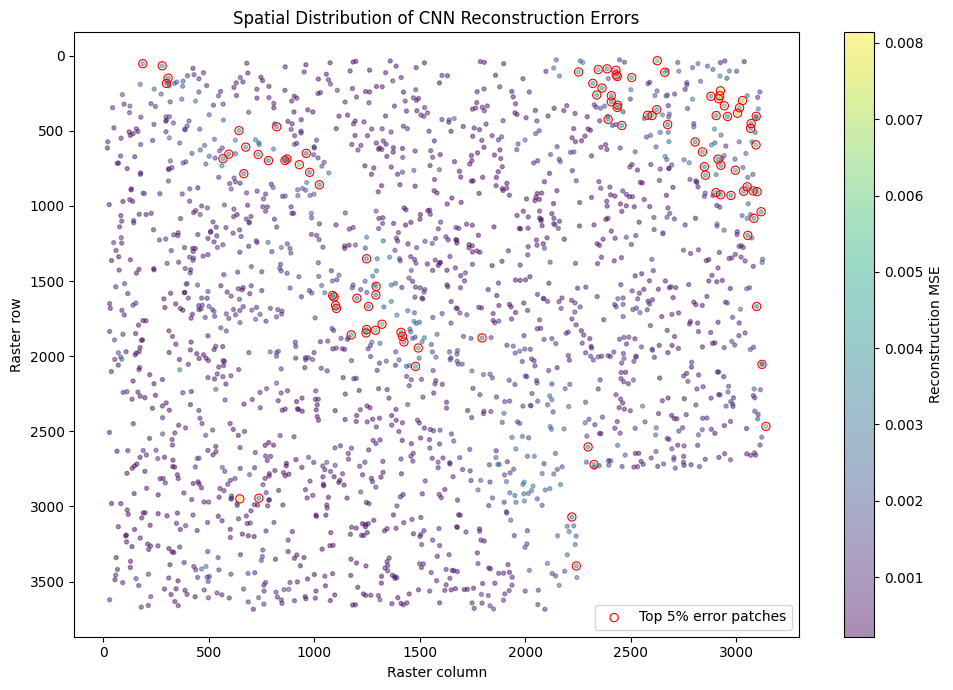

In [43]:
# Step 10: Map sampled patches with high reconstruction error

import matplotlib.pyplot as plt
import numpy as np

# Select the top 5% of patches by reconstruction error
error_threshold = np.percentile(patch_errors, 95)
high_error_mask = patch_errors >= error_threshold

high_error_centres = patch_centres[high_error_mask]
high_error_values = patch_errors[high_error_mask]

print("95th percentile error threshold:", float(error_threshold))
print("High-error patches:", len(high_error_values))

# Plot their locations using raster row and column coordinates
plt.figure(figsize=(10, 7))

plt.scatter(
    patch_centres[:, 1],
    patch_centres[:, 0],
    c=patch_errors,
    s=8,
    cmap="viridis",
    alpha=0.45
)

plt.colorbar(label="Reconstruction MSE")

plt.scatter(
    high_error_centres[:, 1],
    high_error_centres[:, 0],
    facecolors="none",
    edgecolors="red",
    s=35,
    linewidths=0.8,
    label="Top 5% error patches"
)

plt.xlabel("Raster column")
plt.ylabel("Raster row")
plt.title("Spatial Distribution of CNN Reconstruction Errors")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
# Step 11: Compare high-error patch centres with radiometric anomalies

# Check that the existing anomaly map is available
print("Available anomaly-related variables:")
for name in ["anomaly_count", "feature_data", "valid_mask"]:
    print(f"{name}: {name in globals()}")

# Extract anomaly counts at all sampled patch centres.
# This assumes anomaly_count is a 2D raster-shaped array.
if "anomaly_count" in globals():
    if anomaly_count.shape != valid_mask.shape:
        raise ValueError(
            "anomaly_count and valid_mask have different shapes."
        )

    sampled_anomaly_counts = anomaly_count[
        patch_centres[:, 0],
        patch_centres[:, 1]
    ]

    high_error_anomaly_counts = sampled_anomaly_counts[high_error_mask]

    print("\nHigh-error patch comparison")
    print("Total sampled patches:", len(patch_errors))
    print("High-error patches:", int(high_error_mask.sum()))
    print(
        "High-error centres with >=1 radiometric anomaly:",
        int(np.sum(high_error_anomaly_counts > 0))
    )
    print(
        "Percentage of high-error centres with >=1 radiometric anomaly:",
        round(100 * np.mean(high_error_anomaly_counts > 0), 2), "%"
    )
else:
    print(
        "\nThe variable anomaly_count is not available. "
        "Do not rerun earlier cells; send me this output so I can adapt the comparison."
    )

Available anomaly-related variables:
anomaly_count: True
feature_data: True
valid_mask: True

High-error patch comparison
Total sampled patches: 2000
High-error patches: 100
High-error centres with >=1 radiometric anomaly: 67
Percentage of high-error centres with >=1 radiometric anomaly: 67.0 %


In [45]:
# Step 11A: Compare anomaly rates in high-error and other patches

all_centres_anomalous = sampled_anomaly_counts > 0

high_rate = np.mean(all_centres_anomalous[high_error_mask]) * 100
other_rate = np.mean(all_centres_anomalous[~high_error_mask]) * 100
overall_rate = np.mean(all_centres_anomalous) * 100

print(f"Anomaly rate across all sampled centres: {overall_rate:.2f}%")
print(f"Anomaly rate in top 5% error patches:    {high_rate:.2f}%")
print(f"Anomaly rate in remaining patches:       {other_rate:.2f}%")
print(f"Difference (high-error minus remaining):  {high_rate - other_rate:.2f} percentage points")

Anomaly rate across all sampled centres: 7.30%
Anomaly rate in top 5% error patches:    67.00%
Anomaly rate in remaining patches:       4.16%
Difference (high-error minus remaining):  62.84 percentage points


In [46]:
# Step 12: Summarize CNN experiment findings

high_error_rate = 100 * np.mean(high_error_mask)
anomaly_rate_high = 100 * np.mean(
    all_centres_anomalous[high_error_mask]
)
anomaly_rate_other = 100 * np.mean(
    all_centres_anomalous[~high_error_mask]
)

print("""
CNN AUTOENCODER: EXPERIMENT SUMMARY
===================================

Input data:
- Four aligned radiometric channels: K, eU, eTh and Dose
- Patch size: 32 x 32 pixels
- Sampled patches: 2,000
- Training patches: 1,682
- Validation patches: 318

Model:
- Convolutional autoencoder
- Training objective: reconstruct input radiometric patches
- Training epochs: 20
- Final training MSE: {:.6f}
- Final validation MSE: {:.6f}

Reconstruction errors:
- Mean patch error: {:.6f}
- Median patch error: {:.6f}
- 95th-percentile error: {:.6f}
- Highest patch error: {:.6f}

Radiometric anomaly comparison at patch centres:
- High-error patches: {} ({:.1f}% of sampled patches)
- Anomaly rate in high-error patches: {:.2f}%
- Anomaly rate in remaining patches: {:.2f}%
- Difference: {:.2f} percentage points

Interpretation and limitations:
- The autoencoder learned to reconstruct the sampled radiometric patterns.
- High reconstruction errors were associated with existing radiometric
  anomalies in this sample.
- The analysis is exploratory and does not confirm mineral deposits.
- No labelled mineral-deposit data were available for supervised training.
- Spatial independence, statistical significance and geological validity
  have not been established.
- Further work should investigate data quality, spatial validation,
  geological context and independent deposit evidence.
""".format(
    history.history["loss"][-1],
    history.history["val_loss"][-1],
    np.mean(patch_errors),
    np.median(patch_errors),
    np.percentile(patch_errors, 95),
    np.max(patch_errors),
    int(high_error_mask.sum()),
    high_error_rate,
    anomaly_rate_high,
    anomaly_rate_other,
    anomaly_rate_high - anomaly_rate_other
))


CNN AUTOENCODER: EXPERIMENT SUMMARY

Input data:
- Four aligned radiometric channels: K, eU, eTh and Dose
- Patch size: 32 x 32 pixels
- Sampled patches: 2,000
- Training patches: 1,682
- Validation patches: 318

Model:
- Convolutional autoencoder
- Training objective: reconstruct input radiometric patches
- Training epochs: 20
- Final training MSE: 0.001105
- Final validation MSE: 0.001647

Reconstruction errors:
- Mean patch error: 0.001136
- Median patch error: 0.000785
- 95th-percentile error: 0.003354
- Highest patch error: 0.008140

Radiometric anomaly comparison at patch centres:
- High-error patches: 100 (5.0% of sampled patches)
- Anomaly rate in high-error patches: 67.00%
- Anomaly rate in remaining patches: 4.16%
- Difference: 62.84 percentage points

Interpretation and limitations:
- The autoencoder learned to reconstruct the sampled radiometric patterns.
- High reconstruction errors were associated with existing radiometric
  anomalies in this sample.
- The analysis is ex